In [1]:
import os

import numpy as np

import matplotlib.pyplot as plt

from scipy.stats import poisson, nbinom, beta as beta_dist, norm



plt.rcParams.update({

    'figure.dpi': 300,

    'font.size': 18,

})



# Consistent styling across all figures.

PALETTE = ['#7b00ff', '#2196F3', '#E91E63', '#4CAF50', '#F57C00', '#C62828']

LW = 2.0

REF_LW = 1.5



os.makedirs('figures', exist_ok=True)



kmax = 2000

k = np.arange(kmax + 1)



In [2]:
def pk_pl(g):
    """Power-law degree PMF p_k ~ k^-g on k = 1..kmax."""
    p = k[1:] ** (-g)
    return p / p.sum()


def mk_pl_tail_mk(g):
    """Mean degree of the power-law distribution, with a tail correction."""
    p = k[1:] ** (-g)
    s1 = (k[1:] * p).sum()
    s0 = p.sum()
    tail1 = kmax ** (2 - g) / (g - 2)
    tail0 = kmax ** (1 - g) / (g - 1)
    return (s1 + tail1) / (s0 + tail0)


def find_contour_y_at_x(x_vals, y_vals, K, x_target):
    """y where the K = 1 contour crosses x = x_target, for label placement."""
    i = np.argmin(np.abs(x_vals - x_target))
    col = K[:, i]
    j = np.where(np.diff(np.sign(col - 1)))[0]
    if len(j) == 0:
        return None
    j = j[0]
    frac = (1 - col[j]) / (col[j + 1] - col[j])
    return y_vals[j] + frac * (y_vals[j + 1] - y_vals[j])


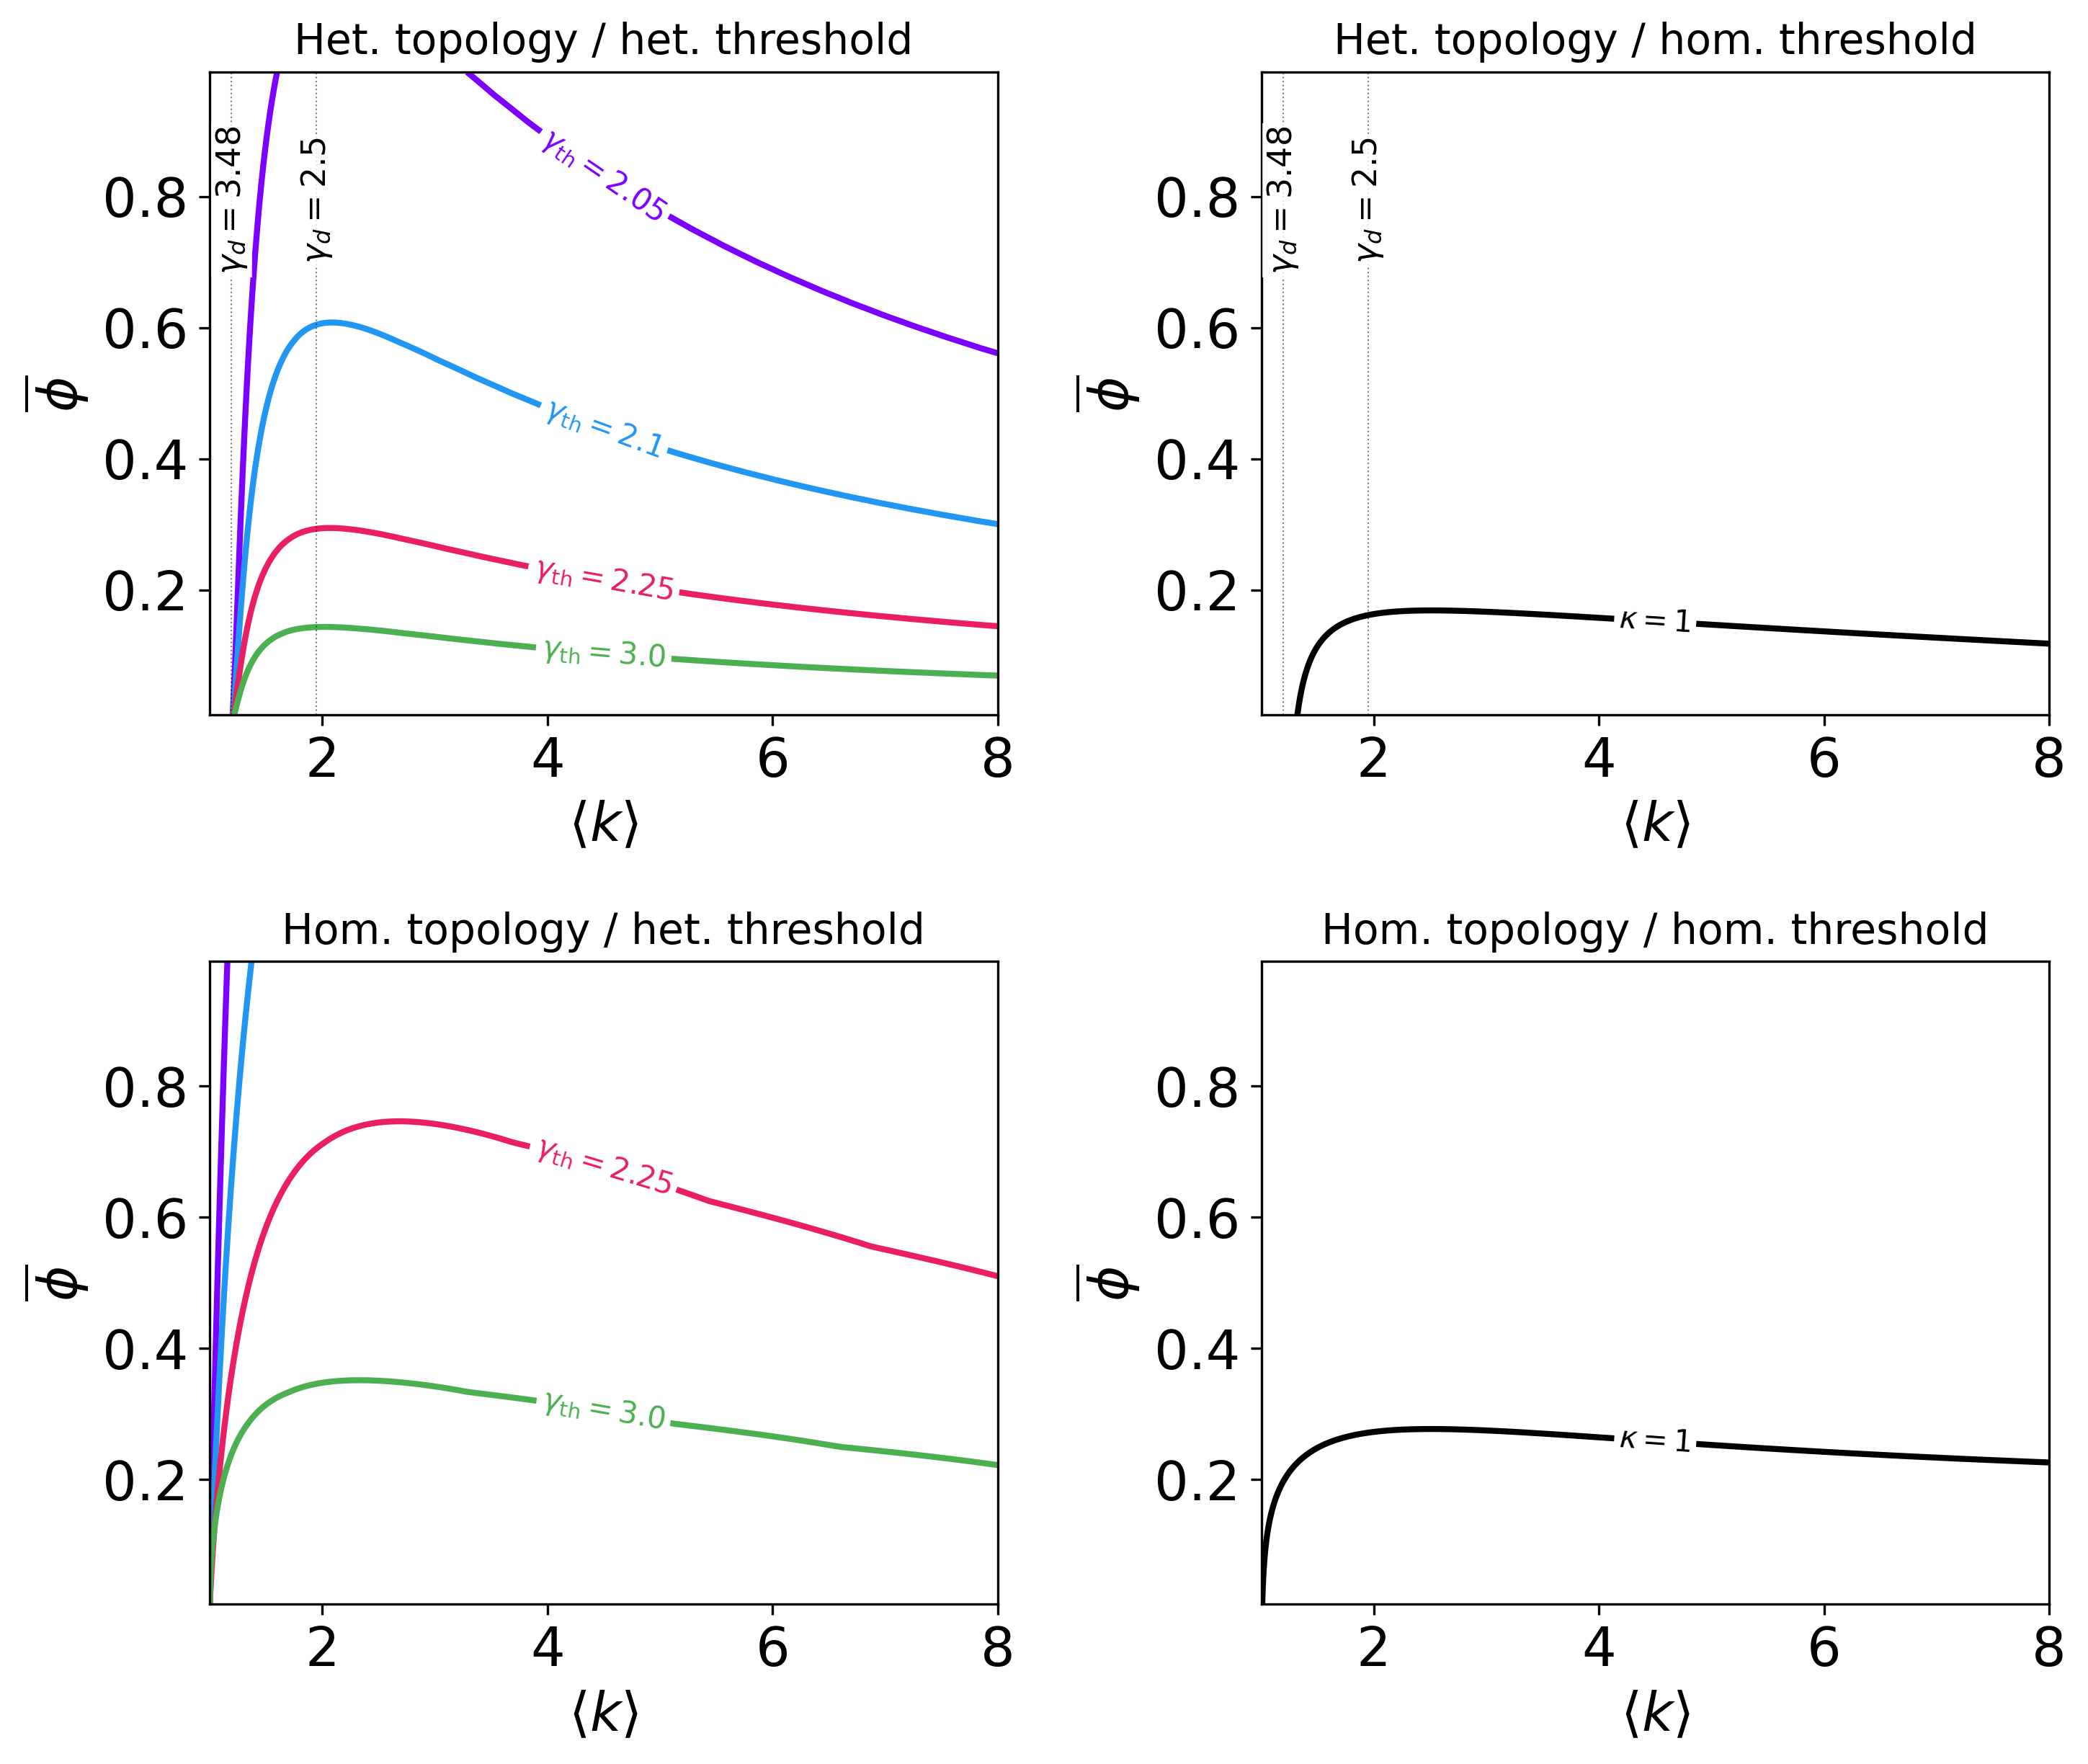

In [3]:
# Figure 1: kappa = 1 contours for the four limiting cases,
# degree (PL / ER) crossed with threshold (Pareto / Gaussian).
sigma_t = 0.1
gamma_ths = [2.05, 2.1, 2.25, 3.0]
colors = PALETTE[:len(gamma_ths)]
titles = ['Het. topology / het. threshold', 'Het. topology / hom. threshold',
          'Hom. topology / het. threshold', 'Hom. topology / hom. threshold']

gammav = np.linspace(2.01, 3.99, 500)
phiv = np.linspace(0.01, 0.99, 500)
zv = np.linspace(1, 8, 500)
x_uni = np.linspace(1, 8, 1000)

# Power-law degree weights and mean degrees on the gamma grid
pl_pk = np.array([pk_pl(g) for g in gammav])
pl_mk = np.array([mk_pl_tail_mk(g) for g in gammav])
pl_w = k[2:] * (k[2:] - 1) * pl_pk[:, 1:]

# Gaussian threshold CDF F(m/k), one row per phi, one column per k
mu = phiv[:, None]
Z = norm.cdf(mu / sigma_t)
F_ga = np.zeros((len(phiv), kmax + 1))
F_ga[:, 1:] = (norm.cdf((1 / k[None, 1:] - mu) / sigma_t) - (1 - Z)) / Z

# Poisson degree weights on the z grid
pk_po = poisson.pmf(k, zv[:, None])
pk_po[:, 0] = 0.0
w_po = k[2:] * (k[2:] - 1) * pk_po[:, 2:]

# Gaussian-threshold kappa, precomputed for both degree types
K_pl_ga = (pl_w @ F_ga[:, 2:].T).T / pl_mk[None, :]
K_po_ga = (w_po @ F_ga[:, 2:].T / zv[:, None]).T
K_pl_ga_u = np.array([np.interp(x_uni, pl_mk[::-1], row)
                      for row in K_pl_ga[:, ::-1]])

fig, axs = plt.subplots(2, 2, figsize=(10, 8.5))

for idx, (ax, title) in enumerate(zip(axs.flat, titles)):
    is_pl = idx < 2           # rows: PL / ER degree
    is_pareto = idx % 2 == 0  # columns: Pareto / Gaussian threshold

    if is_pareto:
        for gth, col in zip(gamma_ths, colors):
            x0 = phiv * (gth - 2) / (gth - 1)
            F_pa = np.where(k[None, :] * x0[:, None] < 1,
                            1 - (k[None, :] * x0[:, None]) ** (gth - 1), 0.0)
            F_pa[:, 0] = 0.0
            if is_pl:
                K = (pl_w @ F_pa[:, 2:].T).T / pl_mk[None, :]
                K = np.array([np.interp(x_uni, pl_mk[::-1], row)
                              for row in K[:, ::-1]])
                xs, ys = x_uni, phiv
            else:
                K = (w_po @ F_pa[:, 2:].T / zv[:, None]).T
                xs, ys = zv, phiv
            cs = ax.contour(xs, ys, K, levels=[1.0], colors=[col], linewidths=LW)
            yp = find_contour_y_at_x(xs, ys, K, 4.5)
            if yp is not None:
                fmt_str = '$\\gamma_{\\mathrm{th}}=' + str(gth) + '$'
                ax.clabel(cs, fmt={1.0: fmt_str}, fontsize=10,
                          colors=[col], inline=True, manual=[(4.5, yp)])
    else:
        if is_pl:
            K, xs, ys = K_pl_ga_u, x_uni, phiv
        else:
            K, xs, ys = K_po_ga, zv, phiv
        cs = ax.contour(xs, ys, K, levels=[1.0], colors=['black'], linewidths=LW)
        yp = find_contour_y_at_x(xs, ys, K, 4.5)
        if yp is not None:
            ax.clabel(cs, fmt={1.0: '$\\kappa=1$'}, fontsize=10,
                      colors=['black'], inline=True, manual=[(4.5, yp)])

    ax.set_xlim(1, 8)
    if is_pl:
        for mk, lab in zip([1.1945, 1.9474],
                           ['$\\gamma_d=3.48$', '$\\gamma_d=2.5$']):
            ax.axvline(mk, color='k', lw=0.5, ls=':', alpha=0.5)
            ax.text(mk, 0.8, lab, transform=ax.get_xaxis_transform(),
                    ha='center', va='center', fontsize=11, rotation=90,
                    rotation_mode='anchor',
                    bbox=dict(fc='white', ec='none', pad=1, alpha=0.8))
    ax.set_xlabel('$\\langle k \\rangle$')
    ax.set_ylabel('$\\overline{\\phi}$')
    ax.set_title(title, fontsize=14)

fig.tight_layout()
fig.savefig('figures/fig1_four_limiting_cases.pdf')
plt.show()


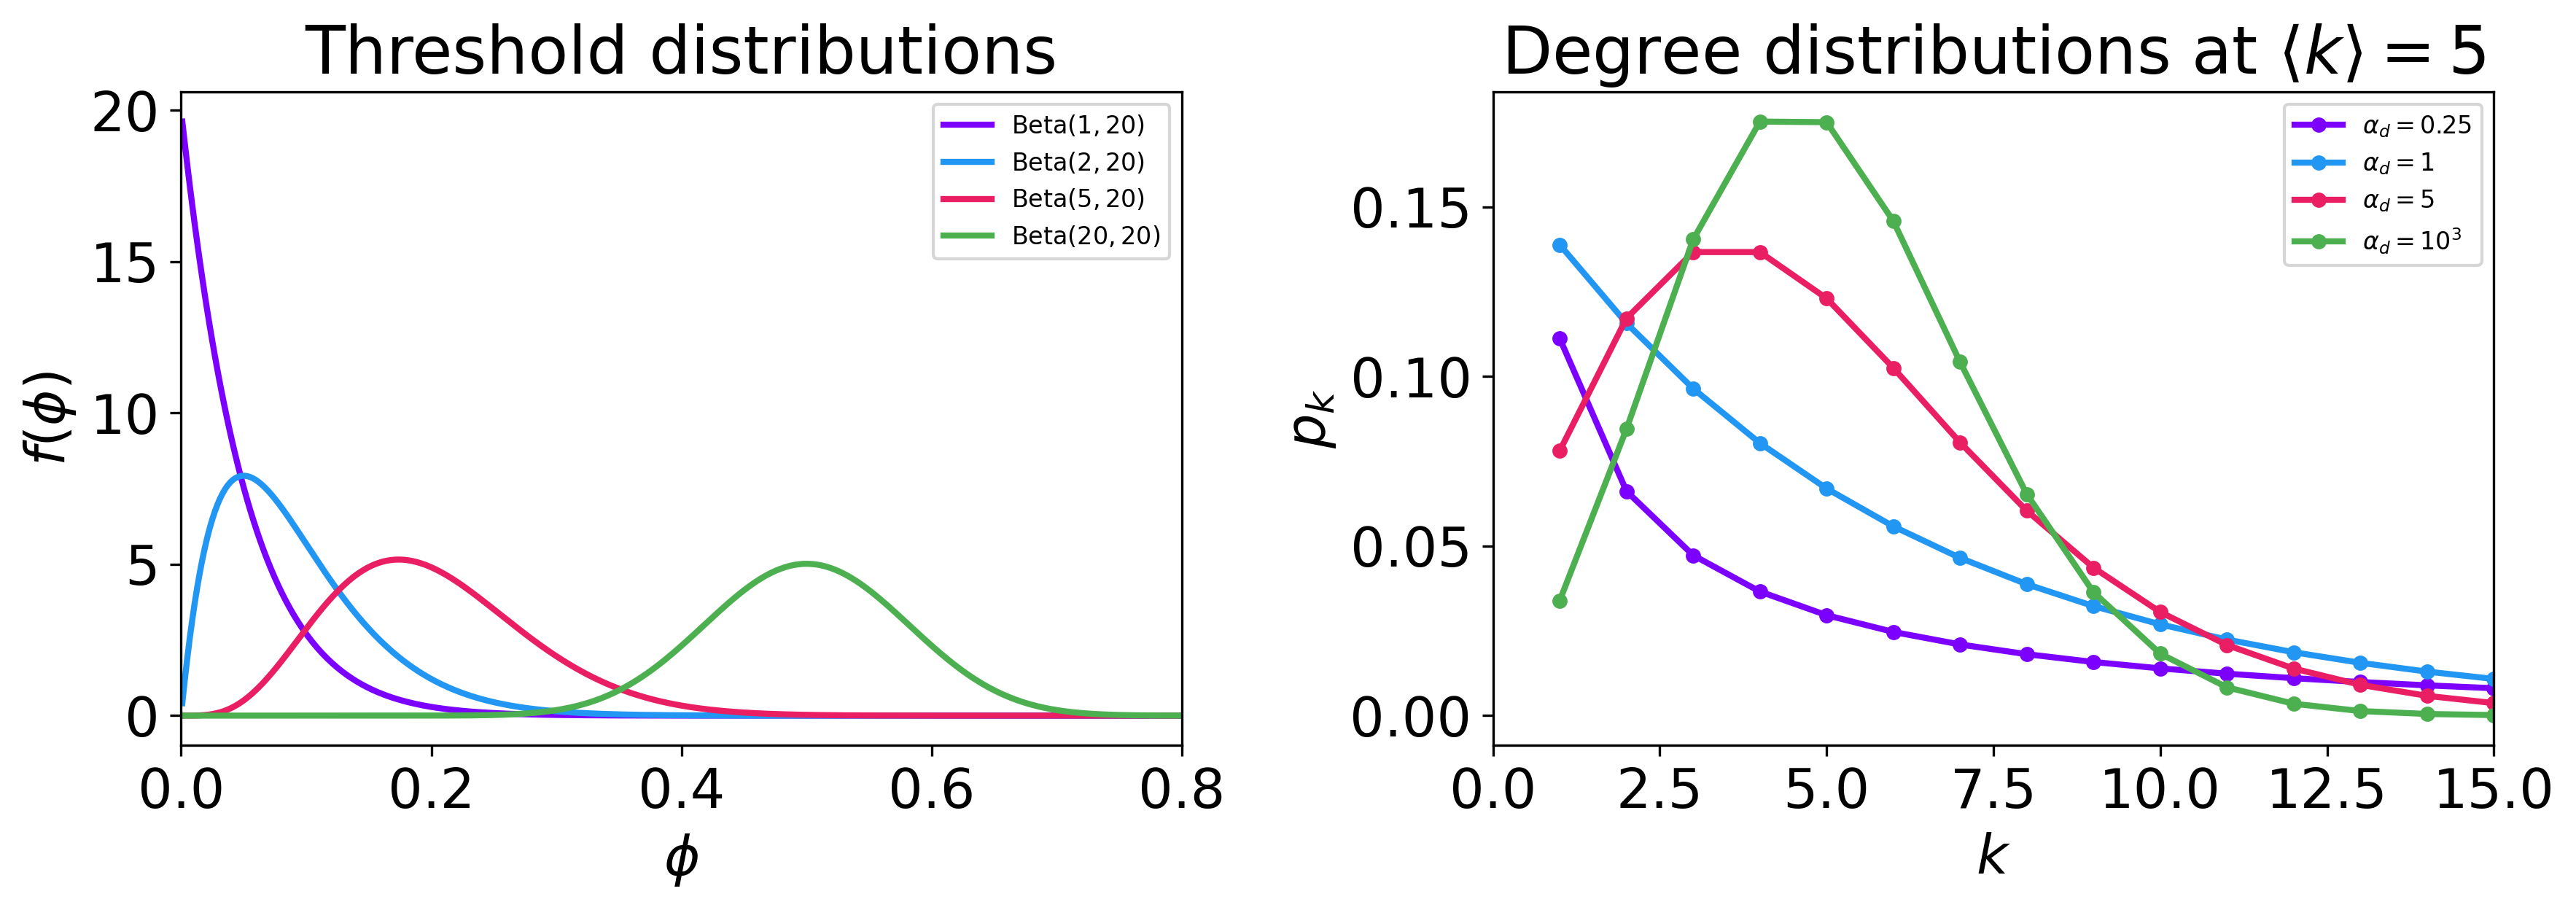

In [4]:
# Figure 2: beta threshold densities and negative-binomial degree PMFs at <k> = 5.

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))



# Threshold densities, heterogeneous -> homogeneous

x = np.linspace(0.001, 0.999, 500)

thr_specs = [

    (1, 20, '$\\mathrm{Beta}(1,20)$'),

    (2, 20, '$\\mathrm{Beta}(2,20)$'),

    (5, 20, '$\\mathrm{Beta}(5,20)$'),

    (20, 20, '$\\mathrm{Beta}(20,20)$'),

]

for (a, b, lab), col in zip(thr_specs, PALETTE):

    axes[0].plot(x, beta_dist.pdf(x, a, b), color=col, lw=LW, label=lab)

axes[0].set_xlabel('$\\phi$')

axes[0].set_ylabel('$f(\\phi)$')

axes[0].set_title('Threshold distributions')

axes[0].legend(fontsize=8)

axes[0].set_xlim(0, 0.8)



# Degree PMFs at <k> = 5, starting at k = 1 (isolates at k = 0 excluded)

kk = np.arange(1, 31)

deg_specs = [

    (0.25,  '$\\alpha_d=0.25$'),

    (1.0,   '$\\alpha_d=1$'),

    (5.0,   '$\\alpha_d=5$'),

    (1000,  '$\\alpha_d=10^3$'),

]

for (ad, lab), col in zip(deg_specs, PALETTE):

    axes[1].plot(kk, nbinom.pmf(kk, ad, ad / (ad + 5)), 'o-',

                 color=col, lw=LW, ms=4, label=lab)

axes[1].set_xlabel('$k$')

axes[1].set_ylabel('$p_k$')

axes[1].set_title('Degree distributions at $\\langle k \\rangle=5$')

axes[1].legend(fontsize=8)

axes[1].set_xlim(0, 15)



fig.tight_layout()

fig.savefig('figures/fig2_nb_distributions.pdf')

plt.show()



In [5]:
def nb_kappa_panel(z_vals, alpha_d, alpha_th, beta_th, phiv, kmax_cap=200):

    """kappa over a (mean degree, mean threshold) grid.



    Degree is NegativeBinomial(alpha_d, mean=z) -- power law with

    exponential cutoff for alpha_d < 1; threshold is Beta(alpha_th,

    beta_th) rescaled to mean phiv, so F(1/k) = I_{m/(k*phiv)}(alpha_th, beta_th).

    """

    m_th = alpha_th / (alpha_th + beta_th)

    kmax_ = kmax_cap

    kk = np.arange(kmax_ + 1)



    pk = nbinom.pmf(kk[None, :], alpha_d, alpha_d / (alpha_d + z_vals[:, None]))

    pk[:, 0] = 0.0

    mk = (kk * pk).sum(axis=1)

    w = kk[2:] * (kk[2:] - 1) * pk[:, 2:]



    arg = np.clip(m_th / (kk[None, 2:] * phiv[:, None] + 1e-30), 0, 1)

    F = beta_dist.cdf(arg, alpha_th, beta_th)

    K = (w @ F.T / mk[:, None]).T

    return z_vals, K



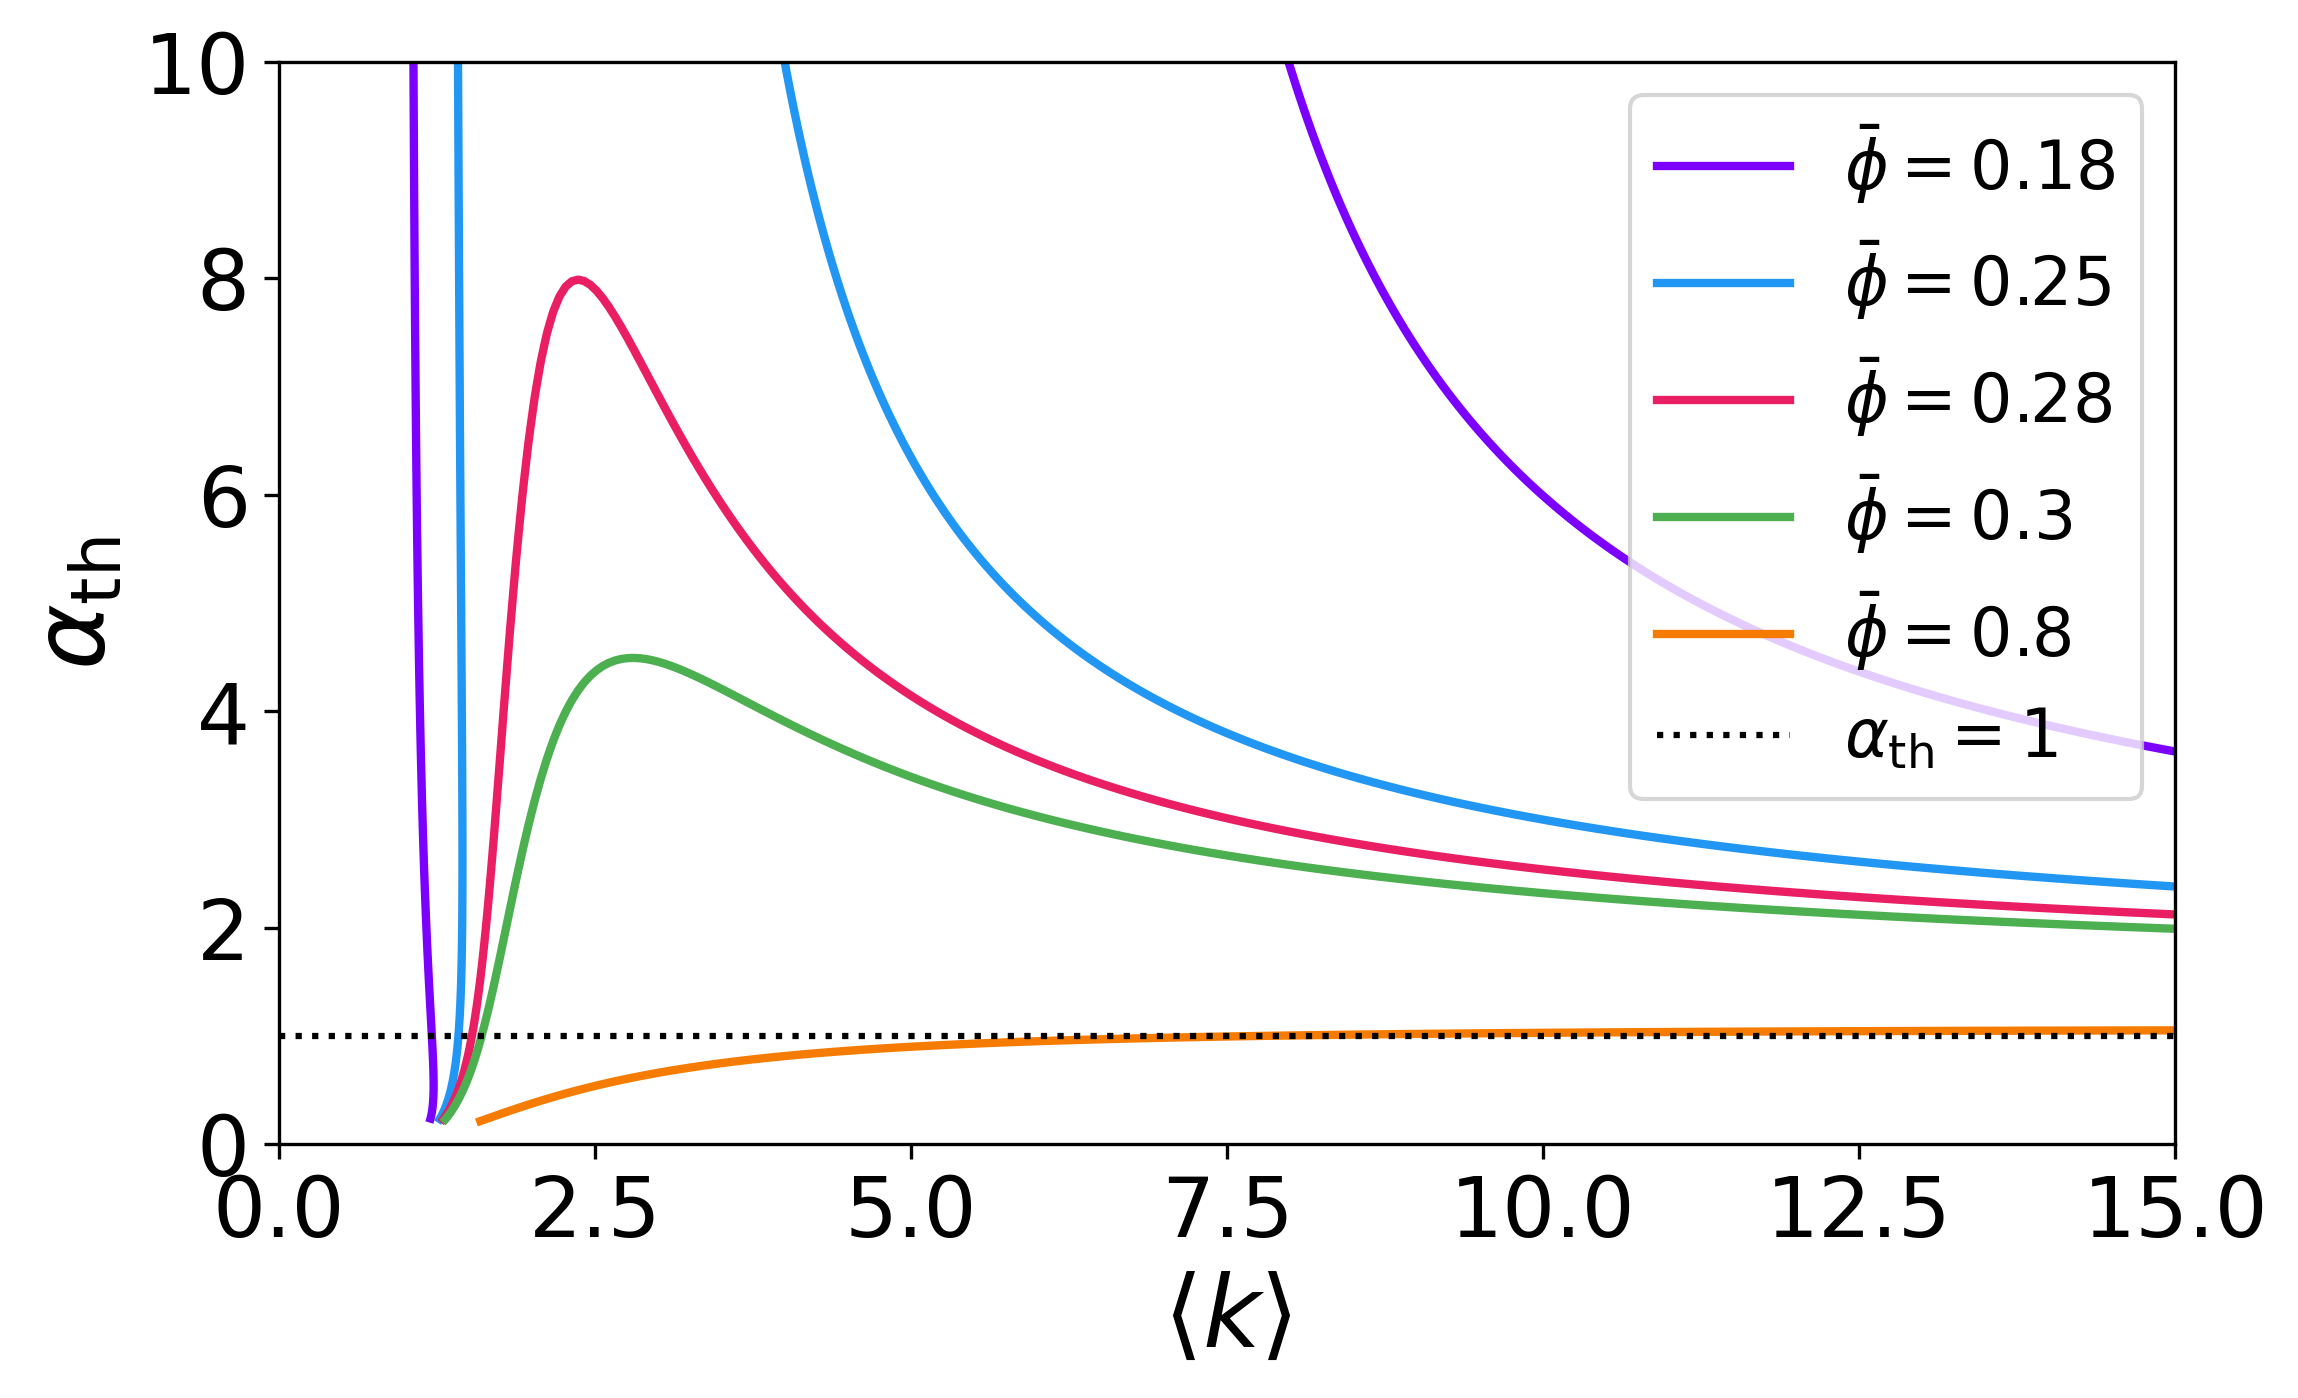

In [6]:
# Figure 3: kappa = 1 contours in (z, alpha_th) space, beta thresholds on ER graphs.
N_az = 1_000_000_000
rho0 = 1.0 / N_az

alpha_vals = np.linspace(0.2, 10, 500)
z_vals = np.linspace(0.5, 25, 500)
B_th = 100
phi_show = [0.18, 0.25, 0.28, 0.3, 0.8]
colors_show = PALETTE[:len(phi_show)]

kmax_az = int(np.floor(z_vals.max() + 10 * np.sqrt(z_vals.max()) + 10))
kk_az = np.arange(1, kmax_az + 1)
W = np.stack([kk_az * (kk_az - 1) / z * poisson.pmf(kk_az, z) for z in z_vals])


def kappa_grid(phi):
    m = alpha_vals / (alpha_vals + B_th)
    arg = np.minimum(1.0, m[:, None] / (kk_az[None, :] * phi))
    F = beta_dist.cdf(arg, alpha_vals[:, None], B_th)
    return (1 - rho0) * F @ W.T


fig, ax = plt.subplots(figsize=(8, 5))
for phi, col in zip(phi_show, colors_show):
    K = kappa_grid(phi)
    ax.contour(z_vals, alpha_vals, K, levels=[1.0], colors=[col], linewidths=LW)
    ax.plot([], [], color=col, linewidth=LW, label=f"$\\bar\\phi={phi}$")
ax.axhline(1.0, color="black", linestyle=":", linewidth=REF_LW, label="$\\alpha_{\\mathrm{th}}=1$")

ax.set_xlim(0, 15)
ax.set_ylim(0, 10)
ax.set_xlabel("$\\langle k \\rangle$", fontsize=24)
ax.set_ylabel("$\\alpha_{\\mathrm{th}}$", fontsize=24)
ax.tick_params(labelsize=20)
ax.legend(loc="upper right", fontsize=16)
fig.tight_layout()
fig.savefig('figures/fig3_alpha_z.pdf')
plt.show()


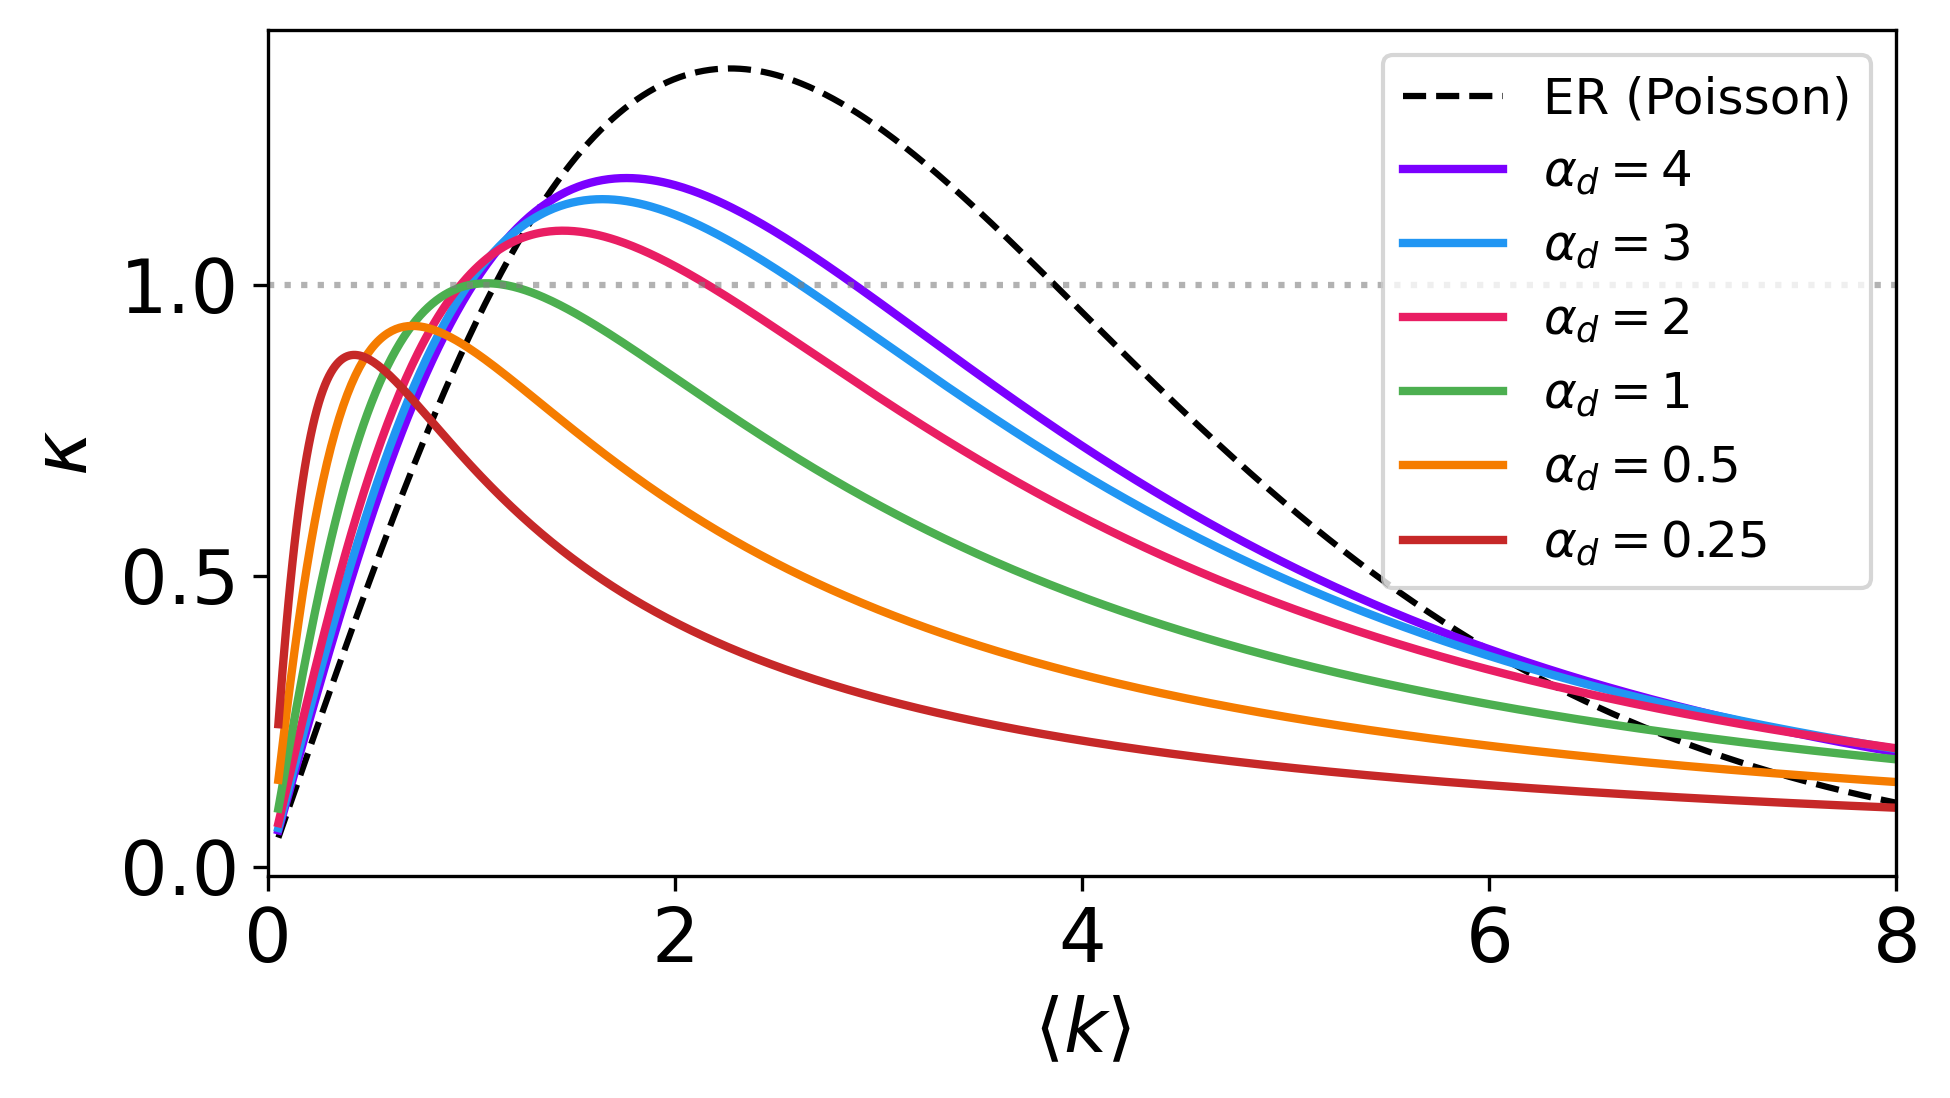

In [7]:
# Figure 4: kappa vs mean degree for negative-binomial degree x constant threshold,

# for a sweep of alpha_d, with the ER reference.

phi = 0.25

k_trig = int(1 / phi)

z_vals = np.linspace(0.05, 8, 800)



alpha_sets = [

    (4.,   '$\\alpha_d=4$'),

    (3.,   '$\\alpha_d=3$'),

    (2.,   '$\\alpha_d=2$'),

    (1.,   '$\\alpha_d=1$'),

    (0.5,  '$\\alpha_d=0.5$'),

    (0.25, '$\\alpha_d=0.25$'),

]



fig, ax = plt.subplots(figsize=(7, 4))



# ER (Poisson) reference curve

kappa_er = []

for z in z_vals:

    pk = poisson.pmf(np.arange(k_trig + 1), z)

    pk[0] = 0.0

    ks = np.arange(k_trig + 1)

    kappa_er.append(np.sum(ks[2:] * (ks[2:] - 1) * pk[2:]) / z)

ax.plot(z_vals, kappa_er, lw=REF_LW, color='black', ls='--', label='ER (Poisson)')



# Negative-binomial curves, one per alpha_d

ks = np.arange(k_trig + 1)

for i, (alpha_d, label) in enumerate(alpha_sets):

    kappas = []

    for z in z_vals:

        pk = nbinom.pmf(ks, alpha_d, alpha_d / (alpha_d + z))

        kappas.append(np.sum(ks[2:] * (ks[2:] - 1) * pk[2:]) / z)

    ax.plot(z_vals, kappas, lw=LW, color=PALETTE[i], label=label)



ax.axhline(1.0, color='gray', ls=':', lw=REF_LW, alpha=0.6)

ax.set_xlabel('$\\langle k \\rangle$')

ax.set_ylabel('$\\kappa$')

ax.legend(fontsize=12, loc='upper right')

ax.set_xlim(0, 8)

fig.tight_layout()

fig.savefig('figures/fig4_nb_kappa_constant_threshold.pdf')

plt.show()



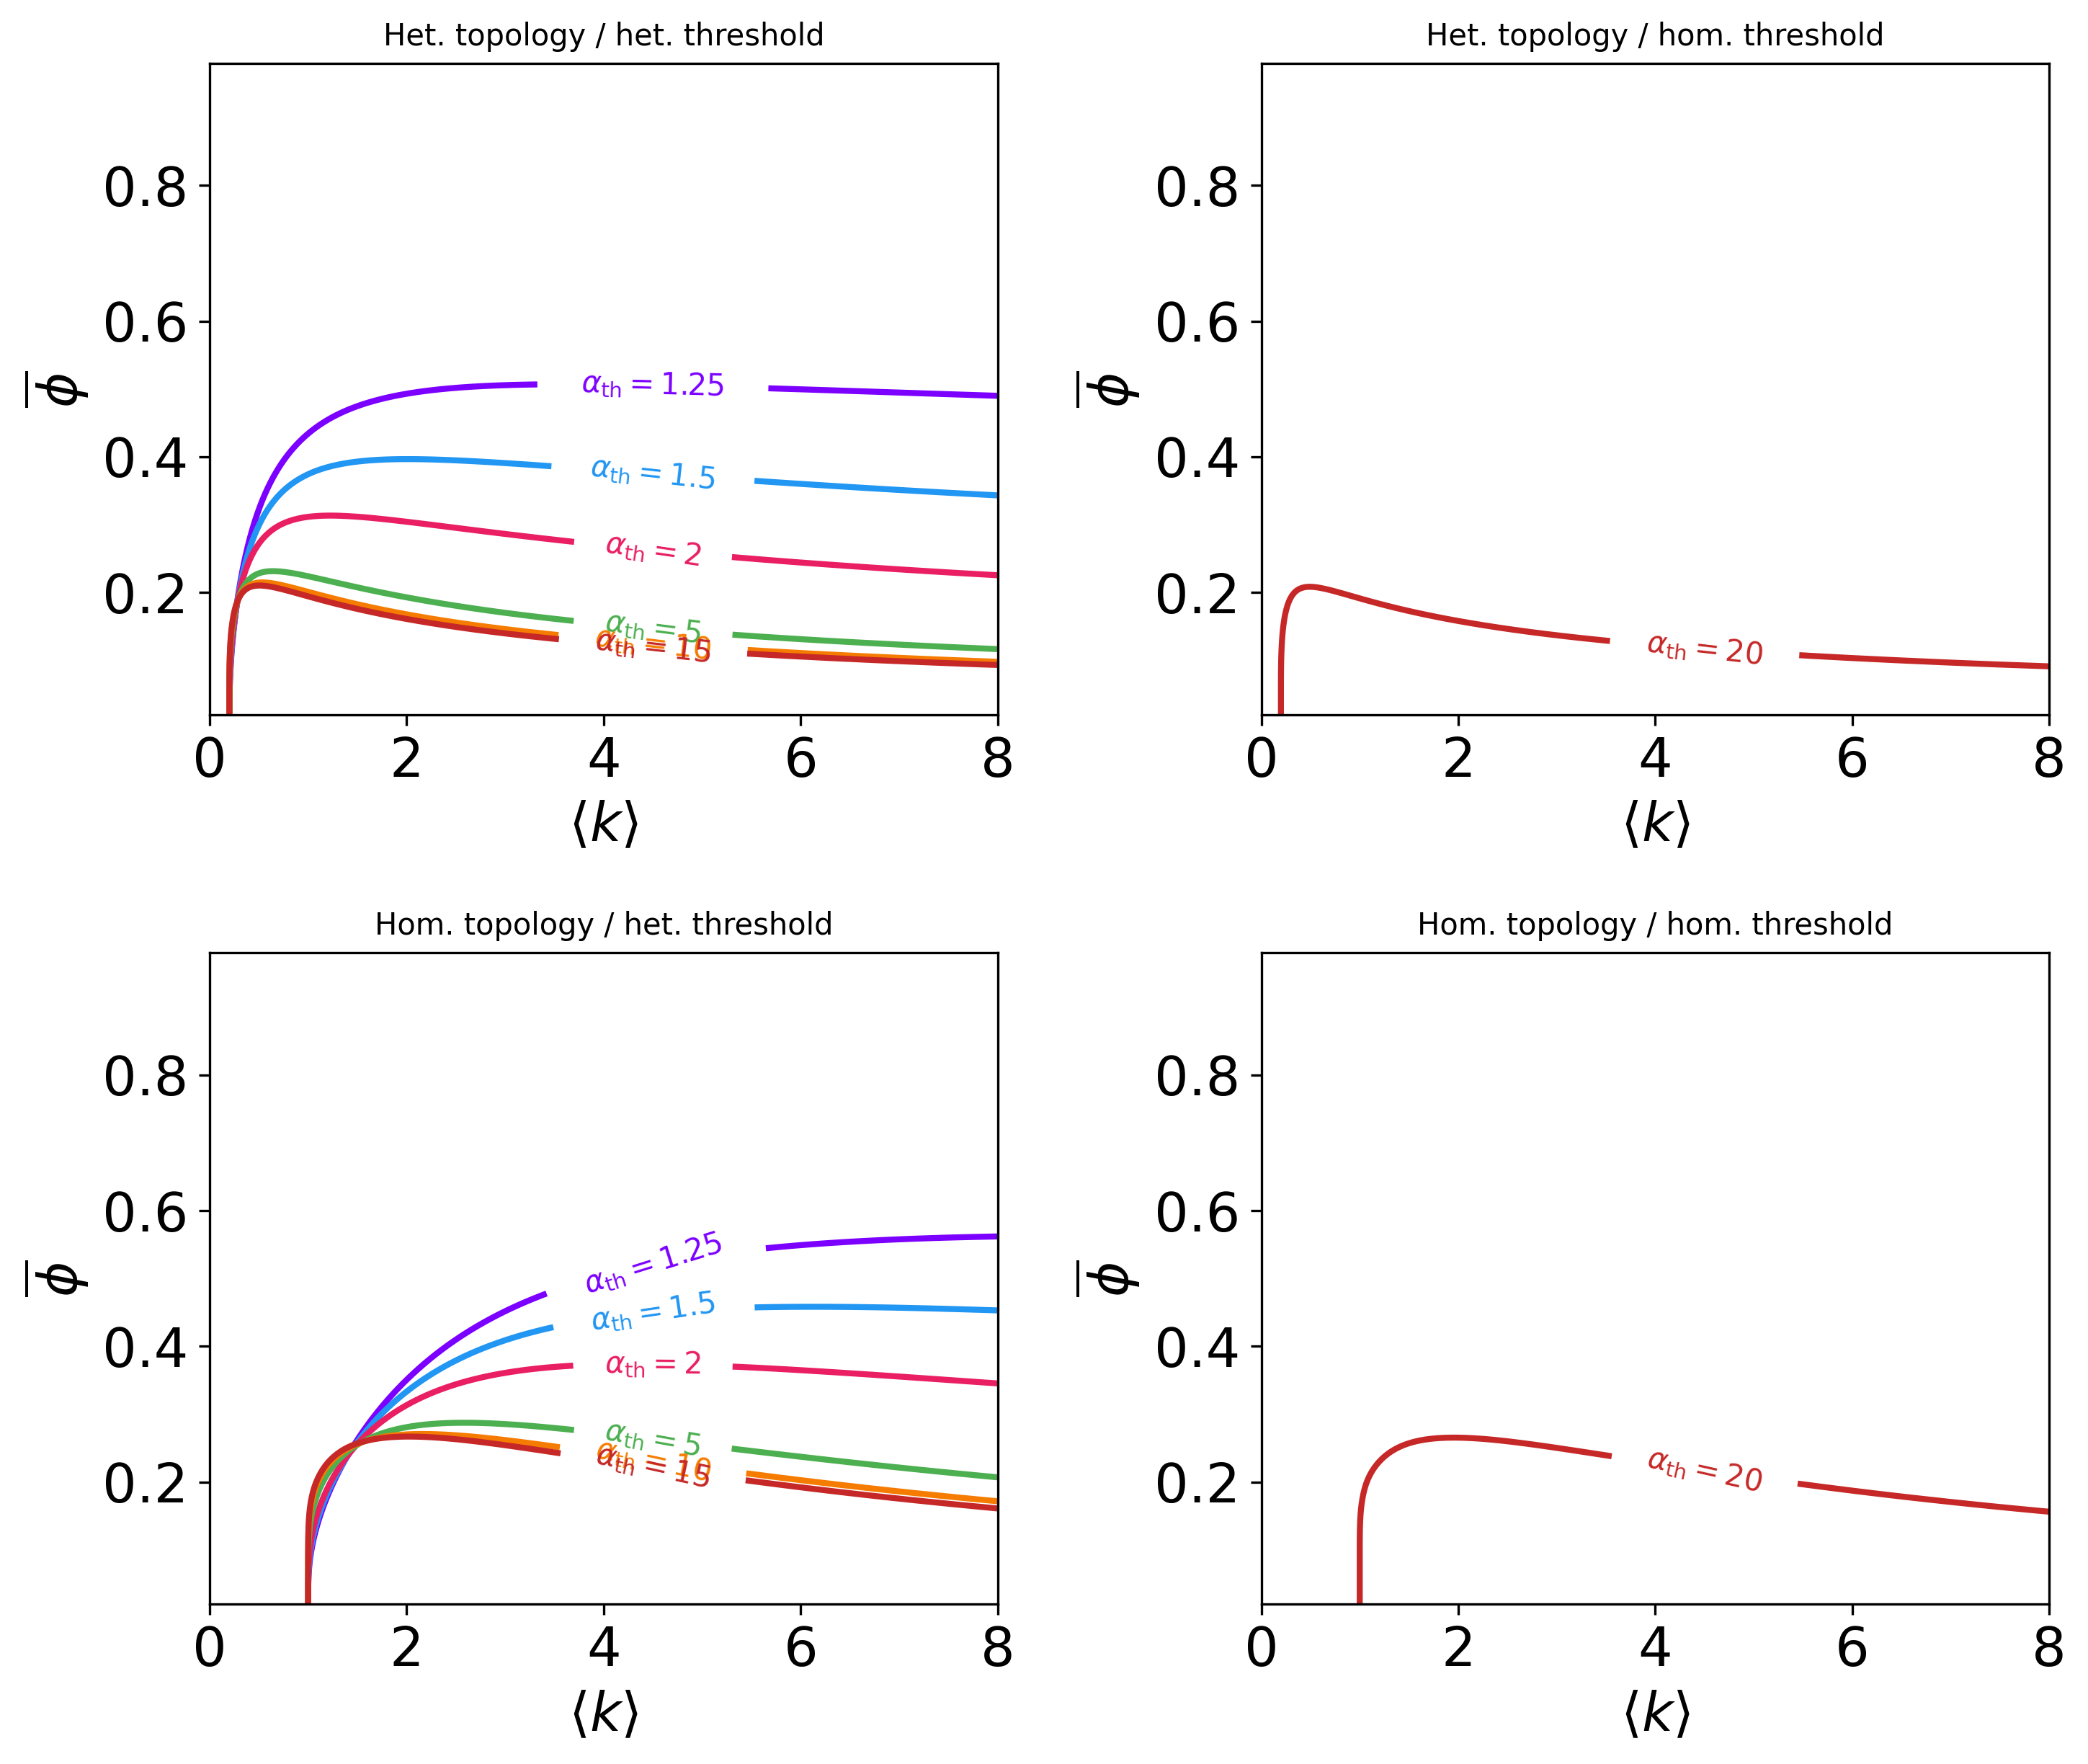

In [8]:
# Figure 5: kappa = 1 contours for negative-binomial degree x Beta threshold,

# the same 2x2 arrangement as Figure 1.

phiv = np.linspace(0.02, 0.98, 300)

kv = np.linspace(0.1, 12, 500)



alpha_d_het = 0.25

alpha_d_hom = 10000



alphas_skew = [1.25, 1.5, 2, 5, 10, 15]

beta_th_fixed = 20

alphas_sym = [20]

colors_skew = PALETTE[:len(alphas_skew)]

color_sym = PALETTE[-1]



titles = ['Het. topology / het. threshold', 'Het. topology / hom. threshold',

          'Hom. topology / het. threshold', 'Hom. topology / hom. threshold']



fig, axs = plt.subplots(2, 2, figsize=(10, 8.5))



for idx, (ax, title) in enumerate(zip(axs.flat, titles)):

    is_het = idx < 2

    is_skew = idx % 2 == 0

    ad = alpha_d_het if is_het else alpha_d_hom



    if is_skew:

        th_vals, th_colors = alphas_skew, colors_skew

    else:

        th_vals, th_colors = alphas_sym, [color_sym]



    for ath, col in zip(th_vals, th_colors):

        if is_skew:

            x_axis, K = nb_kappa_panel(kv, ad, ath, beta_th_fixed, phiv)

        else:

            x_axis, K = nb_kappa_panel(kv, ad, ath, ath, phiv)

        cs = ax.contour(x_axis, phiv, K, levels=[1.0], colors=[col], linewidths=LW)

        yp = find_contour_y_at_x(x_axis, phiv, K, 4.5)

        if yp is not None:

            fmt_str = ('$\\alpha_{\\mathrm{th}}=' + str(ath) + '$')

            ax.clabel(cs, fmt={1.0: fmt_str}, fontsize=10,

                      colors=[col], inline=True, manual=[(4.5, yp)])



    ax.set_xlim(0, 8)

    ax.set_xlabel('$\\langle k \\rangle$')

    ax.set_ylabel('$\\overline{\\phi}$')

    ax.set_title(title, fontsize=10)



fig.tight_layout()

fig.savefig('figures/fig5_nb_contours.pdf')

plt.show()



In [9]:
# Helper: final cascade fraction rho over (mean degree, mean threshold) grids
# via the Gleeson-Cahalane recursion, with stable-branch selection.
from scipy.stats import binom

KMAX_RHO = 200
N_SCAN = 400
KRHO = np.arange(KMAX_RHO + 1)


def precompute_binom():
    """Binomial probability matrices (shared across all threshold panels)."""
    qs = np.linspace(0, 1, N_SCAN)
    B_ex, B_no = [], []
    for kk in range(1, KMAX_RHO + 1):
        B_ex.append(binom.pmf(np.arange(kk), kk - 1, qs[:, None]))
        B_no.append(binom.pmf(np.arange(kk + 1), kk, qs[:, None]))
    return qs, B_ex, B_no


def gh_grids(F_ex, F_no, B_ex, B_no):
    """G(q) = <F_ex> and H(q) = <F_no> over the q scan, per degree k."""
    G_kq = np.zeros((KMAX_RHO + 1, N_SCAN))
    H_kq = np.zeros((KMAX_RHO + 1, N_SCAN))
    for kk in range(1, KMAX_RHO + 1):
        G_kq[kk] = B_ex[kk - 1] @ F_ex[kk, :kk]
        H_kq[kk] = B_no[kk - 1] @ F_no[kk, :kk + 1]
    return G_kq, H_kq


def rho_branch(pk, epk, kappa, qs, G_kq, H_kq):
    """Final cascade fraction for one degree distribution (stable branch).

    Highest stable fixed point when kappa >= 1, otherwise the trivial rho = 0.
    """
    G = epk @ G_kq
    H = pk @ H_kq
    diffs = G - qs
    crosses = np.where(diffs[1:] * diffs[:-1] < 0)[0]
    rs, st = [0.0], [True]  # trivial fixed point q = 0 -> rho = 0
    for i in crosses:
        frac = -diffs[i] / (diffs[i + 1] - diffs[i])
        q_ = qs[i] + frac * (qs[i + 1] - qs[i])
        rs.append(np.interp(q_, qs, H))
        st.append(np.interp(q_, qs, np.gradient(G, qs)) < 1.0)
    if diffs[-1] > 0:  # G(1) > 1: cascade fills the network at q = 1
        rs.append(np.interp(1.0, qs, H))
        st.append(np.interp(1.0, qs, np.gradient(G, qs)) < 1.0)
    stable = [r for r, s in zip(rs, st) if s]
    if not stable:
        return 0.0
    return max(stable) if kappa >= 1.0 else min(stable)


def rho_heatmap(x_points, pk_fn, phi_grid, F_fn, qs, B_ex, B_no,
                exclude_isolates=False):
    """Final cascade fraction R and branching ratio K over (phi, x)."""
    nphi, nx = len(phi_grid), len(x_points)
    R = np.zeros((nphi, nx))
    K = np.zeros((nphi, nx))
    for i, phi in enumerate(phi_grid):
        F_all = F_fn(phi)
        F_ex = np.zeros_like(F_all)
        F_no = np.zeros_like(F_all)
        for kk in range(1, KMAX_RHO + 1):
            F_ex[kk, :kk] = F_all[kk, :kk]
            F_no[kk, :kk + 1] = F_all[kk, :kk + 1]
        G_kq, H_kq = gh_grids(F_ex, F_no, B_ex, B_no)
        for j, p in enumerate(x_points):
            pk = pk_fn(p).astype(float)
            if exclude_isolates:
                pk[0] = 0.0
                s = pk.sum()
                if s < 1e-12:
                    continue
                pk = pk / s
            mk = (KRHO * pk).sum()
            if mk < 1e-10:
                continue
            w = KRHO * (KRHO - 1) * pk
            kappa = (w * F_all[:, 1]).sum() / mk
            K[i, j] = kappa
            R[i, j] = rho_branch(pk, KRHO * pk / mk, kappa, qs, G_kq, H_kq)
    return R, K


/var/folders/l3/dgm693wx7m3b1107vjtfb8k40000gq/T/ipykernel_60175/3558339536.py:76: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


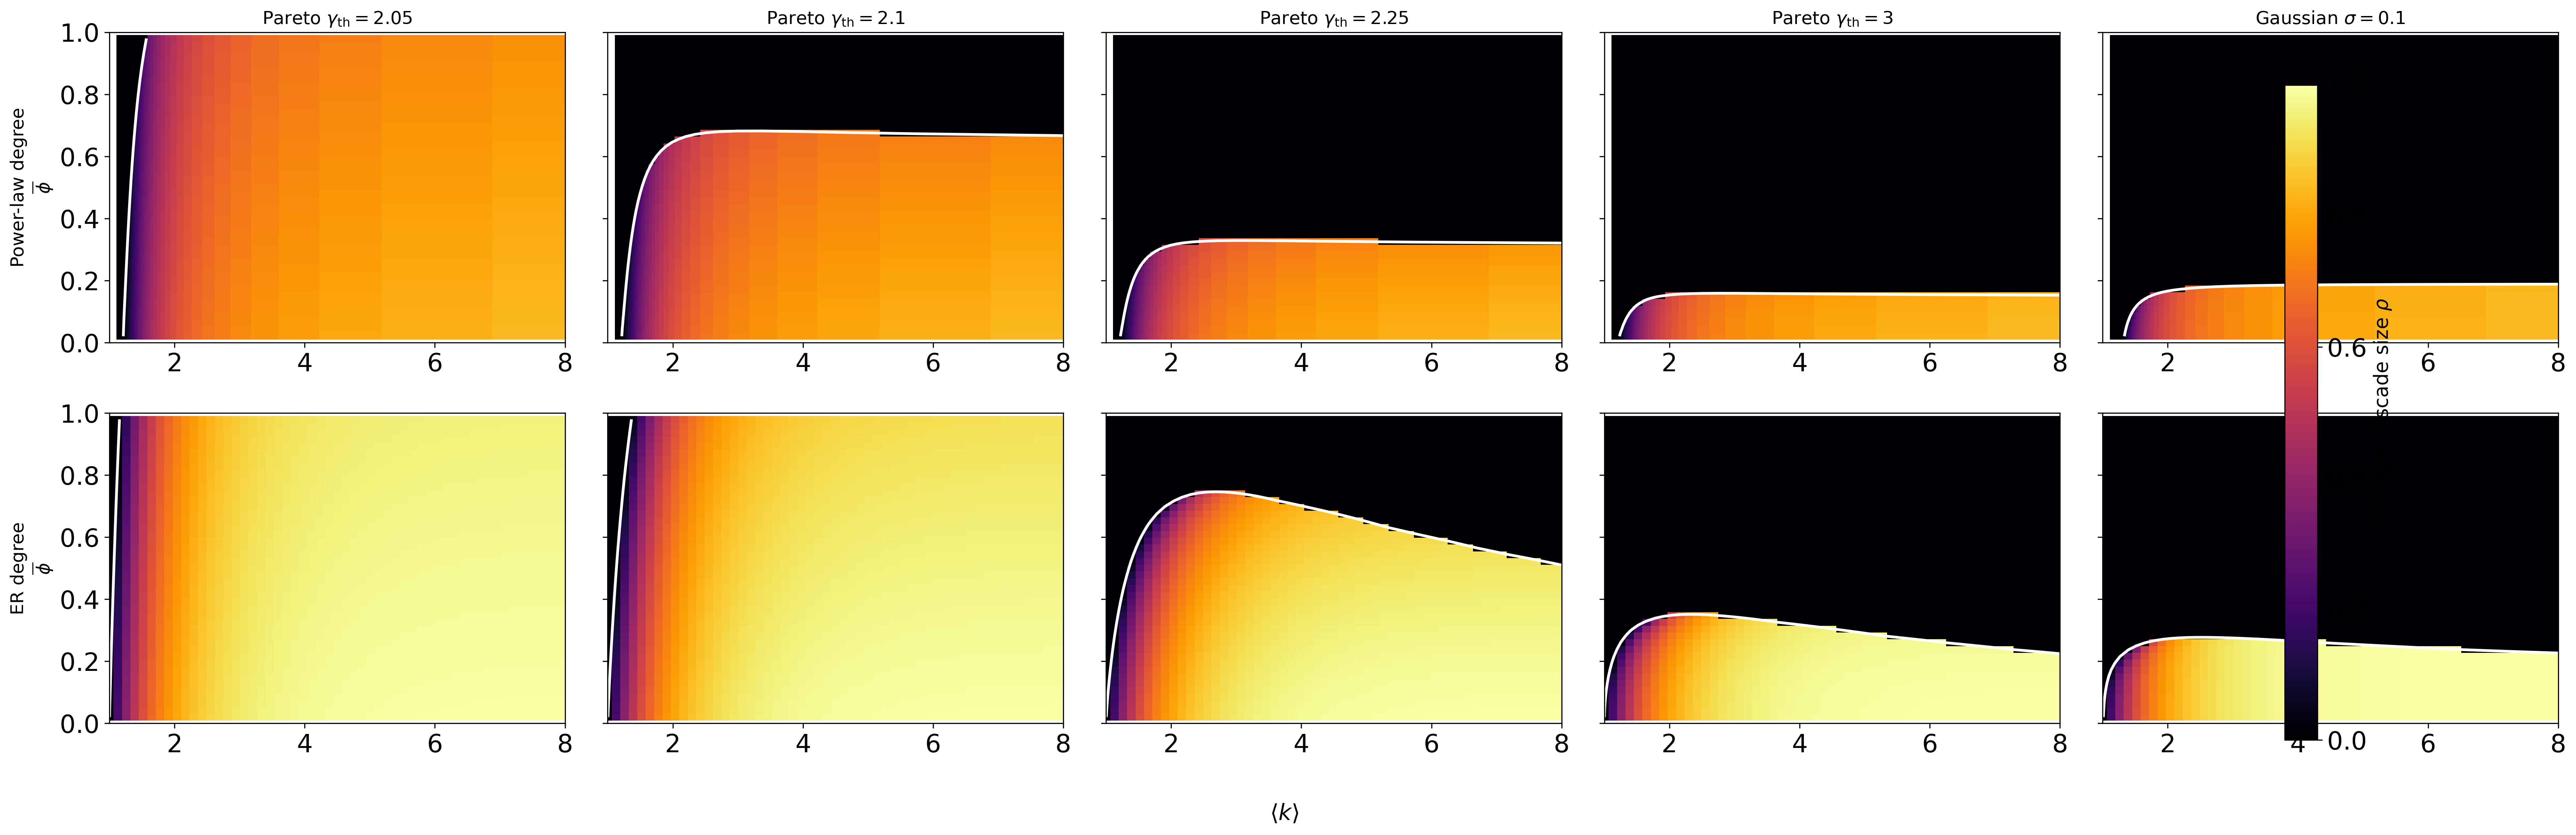

In [10]:
# Figure 6: heatmaps of the average cascade size rho in the (phi, <k>) plane
# for the four limiting cases, one panel per threshold parameter.
sigma_t = 0.1
qs, B_ex, B_no = precompute_binom()

phiv = np.linspace(0.02, 0.98, 45)
zv = np.linspace(1, 8, 55)
gammav = np.linspace(3.99, 2.01, 55)  # descending gamma -> ascending <k>
pl_x = np.array([mk_pl_tail_mk(g) for g in gammav])

kk2 = KRHO[:, None].astype(float)
mm2 = KRHO[None, :].astype(float)
with np.errstate(divide='ignore', invalid='ignore'):
    ratio = np.where(kk2 > 0, mm2 / kk2, 0.0)


def f_pareto(phi, gth):
    x0 = phi * (gth - 2) / (gth - 1)
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where((ratio > x0) & (ratio > 0),
                        1 - np.clip(x0 / ratio, 0, 1) ** (gth - 1), 0.0)


def f_gauss(phi):
    r0 = norm.cdf(0, loc=phi, scale=sigma_t)
    return np.clip((norm.cdf(ratio, loc=phi, scale=sigma_t) - r0) / (1 - r0), 0, 1)


def pk_pl_rho(g):
    p = KRHO[1:] ** (-g)
    return np.concatenate([[0.0], p / p.sum()])


def pk_poi_rho(z):
    return poisson.pmf(KRHO, z)


cols = [
    ('Pareto $\\gamma_{\\rm th}=2.05$', 2.05),
    ('Pareto $\\gamma_{\\rm th}=2.1$', 2.1),
    ('Pareto $\\gamma_{\\rm th}=2.25$', 2.25),
    ('Pareto $\\gamma_{\\rm th}=3$', 3.0),
    ('Gaussian $\\sigma=0.1$', None),
]

fig, axs = plt.subplots(2, len(cols), figsize=(26, 8.5), sharey=True)
ims = []
for j, (ctitle, param) in enumerate(cols):
    F_fn = (lambda phi, p=param: f_pareto(phi, p)) if param is not None else f_gauss

    R_pl, K_pl = rho_heatmap(gammav, pk_pl_rho, phiv, F_fn, qs, B_ex, B_no)
    axs[0, j].pcolormesh(pl_x, phiv, R_pl, cmap='inferno', vmin=0, vmax=1,
                         shading='nearest')
    axs[0, j].contour(pl_x, phiv, K_pl, levels=[1.0], colors='white', linewidths=LW)

    R_po, K_po = rho_heatmap(zv, pk_poi_rho, phiv, F_fn, qs, B_ex, B_no)
    im = axs[1, j].pcolormesh(zv, phiv, R_po, cmap='inferno', vmin=0, vmax=1,
                              shading='nearest')
    axs[1, j].contour(zv, phiv, K_po, levels=[1.0], colors='white', linewidths=LW)

    ims.append(im)
    axs[0, j].set_title(ctitle, fontsize=13)
    for ax in (axs[0, j], axs[1, j]):
        ax.set_xlim(1, 8)
        ax.set_ylim(0, 1)

# sanity: rho ~ 0 wherever kappa < 1, and global cascades where kappa > 1
assert np.mean(R_po[K_po < 1.0]) < 1e-3
assert np.mean(R_po[K_po >= 1.0]) > 1e-2

axs[0, 0].set_ylabel('Power-law degree\n$\\overline{\\phi}$', fontsize=13)
axs[1, 0].set_ylabel('ER degree\n$\\overline{\\phi}$', fontsize=13)
fig.supxlabel('$\\langle k \\rangle$', fontsize=16)
cbar = fig.colorbar(ims[0], ax=axs, fraction=0.02, pad=0.02)
cbar.set_label('average cascade size $\\rho$', fontsize=14)
fig.tight_layout()
fig.savefig('figures/fig6_four_cases_rho.pdf')
plt.show()


/var/folders/l3/dgm693wx7m3b1107vjtfb8k40000gq/T/ipykernel_60175/3410668416.py:107: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


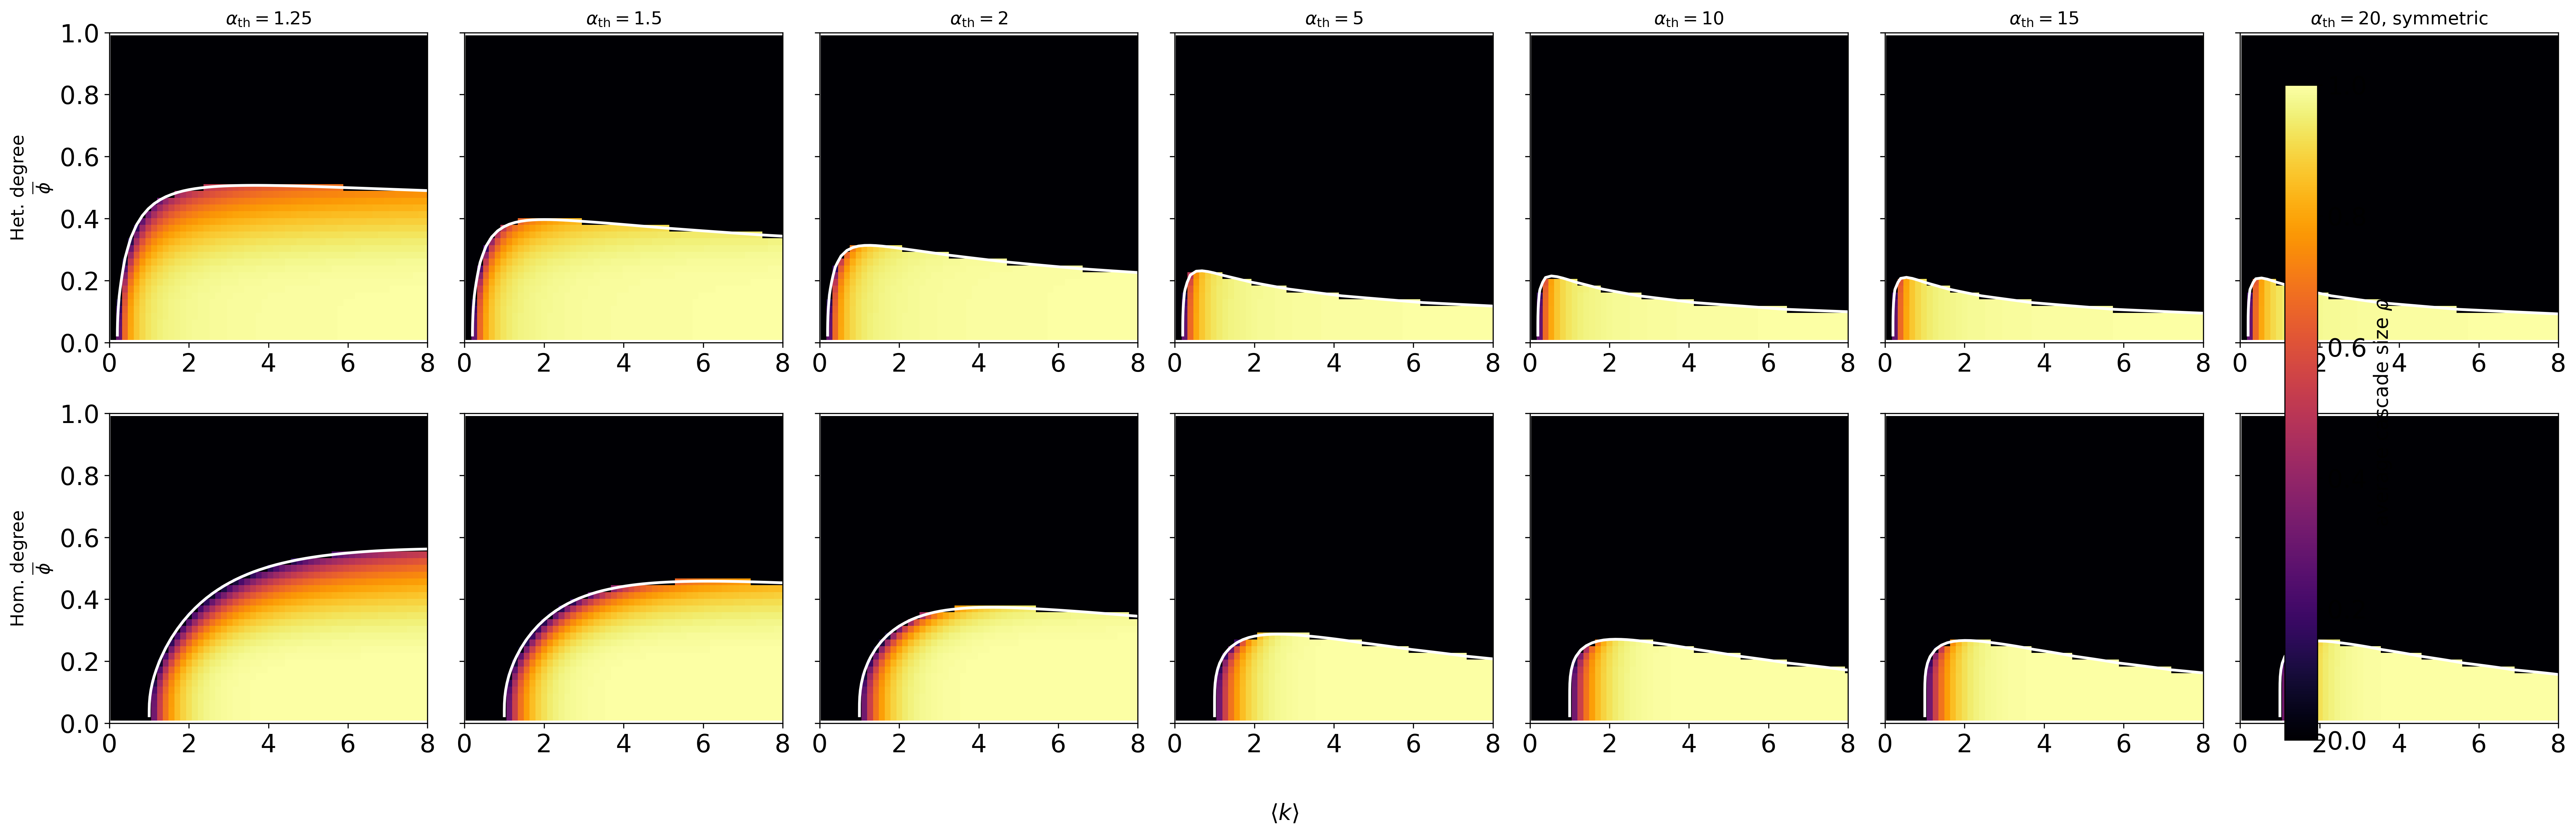

In [11]:
# Figure 7: heatmaps of rho for negative-binomial degree x Beta threshold,

# one panel per (alpha_th, beta_th).

phiv = np.linspace(0.02, 0.98, 45)

kv = np.linspace(0.1, 8, 55)



alpha_d_het = 0.25

alpha_d_hom = 10000

beta_th_fixed = 20



thr_cols = [

    ('$\\alpha_{\\rm th}=1.25$', (1.25, beta_th_fixed)),

    ('$\\alpha_{\\rm th}=1.5$', (1.5, beta_th_fixed)),

    ('$\\alpha_{\\rm th}=2$', (2, beta_th_fixed)),

    ('$\\alpha_{\\rm th}=5$', (5, beta_th_fixed)),

    ('$\\alpha_{\\rm th}=10$', (10, beta_th_fixed)),

    ('$\\alpha_{\\rm th}=15$', (15, beta_th_fixed)),

    ('$\\alpha_{\\rm th}=20$, symmetric', (20, 20)),

]





def f_beta_rescaled(phi, ath, bth):

    m_th = ath / (ath + bth)

    arg = np.clip(mm2 * m_th / (kk2 * phi + 1e-30), 0, 1)

    return beta_dist.cdf(arg, ath, bth)





def make_pk_nb(ad):

    def pk_nb(mk):

        return nbinom.pmf(KRHO, ad, ad / (ad + mk))

    return pk_nb





fig, axs = plt.subplots(2, len(thr_cols), figsize=(26, 8.5), sharey=True)

ims = []

for j, (ctitle, (ath, bth)) in enumerate(thr_cols):

    F_fn = lambda phi, a=ath, b=bth: f_beta_rescaled(phi, a, b)

    for i, ad in enumerate([alpha_d_het, alpha_d_hom]):

        R, K = rho_heatmap(kv, make_pk_nb(ad), phiv, F_fn,

                           qs, B_ex, B_no, exclude_isolates=True)

        ax = axs[i, j]

        im = ax.pcolormesh(kv, phiv, R, cmap='inferno', vmin=0, vmax=1,

                           shading='nearest')

        ax.contour(kv, phiv, K, levels=[1.0], colors='white', linewidths=LW)

        ax.set_xlim(0, 8)

        ax.set_ylim(0, 1)

    ims.append(im)

    axs[0, j].set_title(ctitle, fontsize=13)



axs[0, 0].set_ylabel('Het. degree\n$\\overline{\\phi}$', fontsize=13)

axs[1, 0].set_ylabel('Hom. degree\n$\\overline{\\phi}$', fontsize=13)

fig.supxlabel('$\\langle k \\rangle$', fontsize=16)

cbar = fig.colorbar(ims[0], ax=axs, fraction=0.02, pad=0.02)

cbar.set_label('average cascade size $\\rho$', fontsize=14)

fig.tight_layout()

fig.savefig('figures/fig7_nb_rho.pdf')

plt.show()

